In [ ]:
import numpy as np
import pandas as pd 
import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

import kagglehub

/kaggle/input/datasets/sartajbhuvaji/brain-tumor-classification-mri/Testing/glioma_tumor/image(1).jpg
/kaggle/input/datasets/sartajbhuvaji/brain-tumor-classification-mri/Testing/glioma_tumor/image(10).jpg
/kaggle/input/datasets/sartajbhuvaji/brain-tumor-classification-mri/Testing/glioma_tumor/image(100).jpg
/kaggle/input/datasets/sartajbhuvaji/brain-tumor-classification-mri/Testing/glioma_tumor/image(11).jpg
/kaggle/input/datasets/sartajbhuvaji/brain-tumor-classification-mri/Testing/glioma_tumor/image(12).jpg
/kaggle/input/datasets/sartajbhuvaji/brain-tumor-classification-mri/Testing/glioma_tumor/image(13).jpg
/kaggle/input/datasets/sartajbhuvaji/brain-tumor-classification-mri/Testing/glioma_tumor/image(14).jpg
/kaggle/input/datasets/sartajbhuvaji/brain-tumor-classification-mri/Testing/glioma_tumor/image(15).jpg
/kaggle/input/datasets/sartajbhuvaji/brain-tumor-classification-mri/Testing/glioma_tumor/image(16).jpg
/kaggle/input/datasets/sartajbhuvaji/brain-tumor-classification-mri/Testi

In [ ]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms, models
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

def seed_everything(seed=42):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

seed_everything(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using Device: {device} ({torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU'})")

train_dir, test_dir = None, None
for root, dirs, files in os.walk('/kaggle/input'):
    for d in dirs:
        if d.lower() == 'training':
            train_dir = os.path.join(root, d)
        elif d.lower() == 'testing':
            test_dir = os.path.join(root, d)

print(f"Training Directory : {train_dir}")
print(f"Testing Directory  : {test_dir}")

Using Device: cuda (Tesla T4)
Training Directory : /kaggle/input/datasets/sartajbhuvaji/brain-tumor-classification-mri/Training
Testing Directory  : /kaggle/input/datasets/sartajbhuvaji/brain-tumor-classification-mri/Testing


✅ Training Directory : /kaggle/input/datasets/sartajbhuvaji/brain-tumor-classification-mri/Training
✅ Testing Directory  : /kaggle/input/datasets/sartajbhuvaji/brain-tumor-classification-mri/Testing

Dataset Distribution:
                   Training  Testing
glioma_tumor           826      100
meningioma_tumor       822      115
no_tumor               395      105
pituitary_tumor        827       74


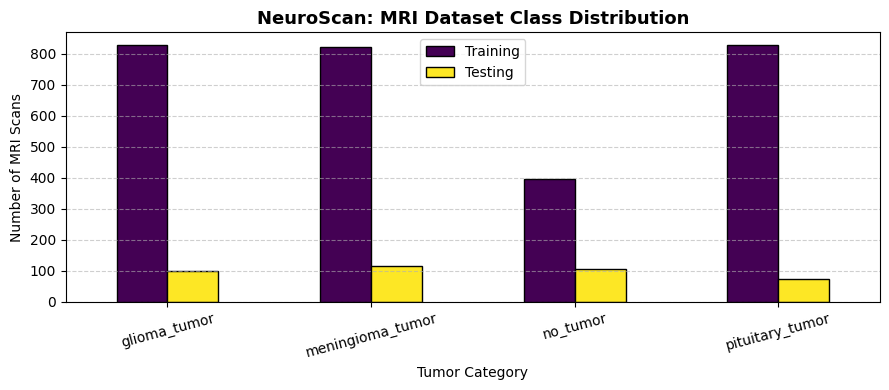

In [ ]:
import os
import kagglehub
import pandas as pd
import matplotlib.pyplot as plt

train_dir, test_dir = None, None

for root, dirs, files in os.walk('/kaggle/input'):
    for d in dirs:
        if d.lower() in ['training', 'train']:
            train_dir = os.path.join(root, d)
        elif d.lower() in ['testing', 'test']:
            test_dir = os.path.join(root, d)

if train_dir is None or test_dir is None:
    print("Sidebar mein dataset nahi mila, kagglehub se mount kar rahe hain...")
    dataset_path = kagglehub.dataset_download('sartajbhuvaji/brain-tumor-classification-mri')
    for root, dirs, files in os.walk(dataset_path):
        for d in dirs:
            if d.lower() in ['training', 'train']:
                train_dir = os.path.join(root, d)
            elif d.lower() in ['testing', 'test']:
                test_dir = os.path.join(root, d)

print(f"✅ Training Directory : {train_dir}")
print(f"✅ Testing Directory  : {test_dir}")

def get_class_counts(directory):
    classes = sorted(os.listdir(directory))
    counts = {
        cls: len(os.listdir(os.path.join(directory, cls)))
        for cls in classes
        if os.path.isdir(os.path.join(directory, cls))
    }
    return counts

train_counts = get_class_counts(train_dir)
test_counts = get_class_counts(test_dir)

df_eda = pd.DataFrame({'Training': train_counts, 'Testing': test_counts})
print("\nDataset Distribution:\n", df_eda)

df_eda.plot(kind='bar', figsize=(9, 4), colormap='viridis', edgecolor='black')
plt.title("NeuroScan: MRI Dataset Class Distribution", fontsize=13, fontweight='bold')
plt.xlabel("Tumor Category")
plt.ylabel("Number of MRI Scans")
plt.xticks(rotation=15)
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

Using Device: cuda
Detected Classes (4): ['glioma_tumor', 'meningioma_tumor', 'no_tumor', 'pituitary_tumor']
Samples -> Train: 2439 | Val: 431 | Test: 394


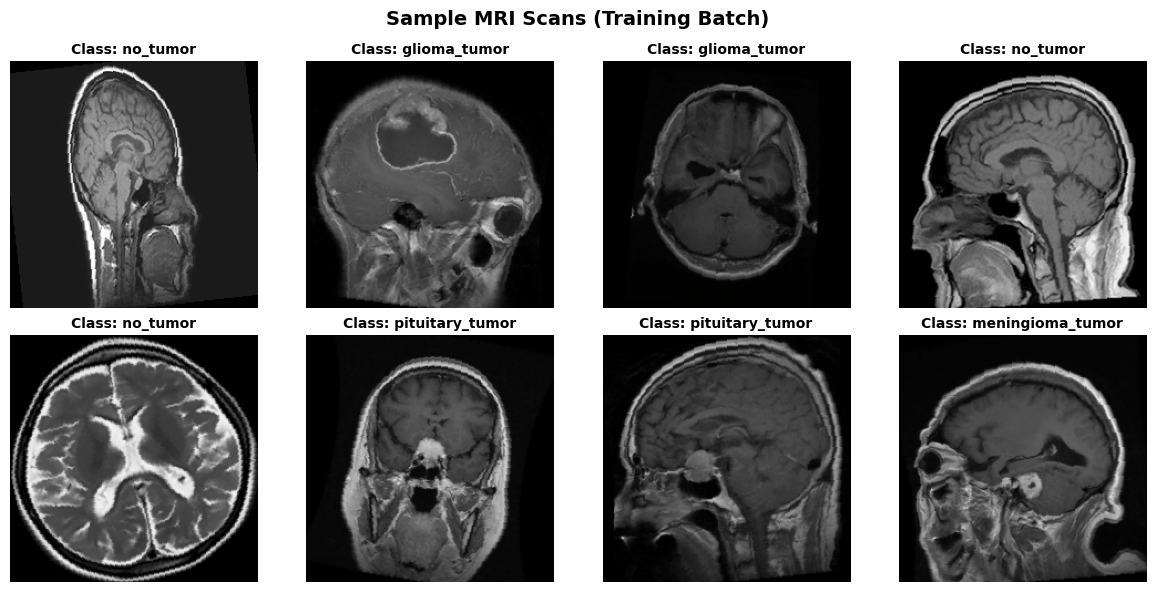

In [ ]:
import random
import numpy as np
import seaborn as sns
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms, models
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

def seed_everything(seed=42):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

seed_everything(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using Device: {device}")

IMG_SIZE = 224
BATCH_SIZE = 32

mean, std = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

train_transforms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(brightness=0.1, contrast=0.1),
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

eval_transforms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

full_train_aug = datasets.ImageFolder(train_dir, transform=train_transforms)
full_train_clean = datasets.ImageFolder(train_dir, transform=eval_transforms)
test_dataset = datasets.ImageFolder(test_dir, transform=eval_transforms)

class_names = full_train_aug.classes
num_classes = len(class_names)
print(f"Detected Classes ({num_classes}): {class_names}")
targets = full_train_aug.targets
train_idx, val_idx = train_test_split(
    np.arange(len(targets)), test_size=0.15, stratify=targets, random_state=42
)

train_dataset = Subset(full_train_aug, train_idx)
val_dataset = Subset(full_train_clean, val_idx)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2, pin_memory=True)
val_loader   = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
test_loader  = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)

print(f"Samples -> Train: {len(train_dataset)} | Val: {len(val_dataset)} | Test: {len(test_dataset)}")

images, labels = next(iter(train_loader))

plt.figure(figsize=(12, 6))
for i in range(8):
    plt.subplot(2, 4, i + 1)
    img = images[i].permute(1, 2, 0).numpy()
    img = std * img + mean 
    img = np.clip(img, 0, 1)
    plt.imshow(img)
    plt.title(f"Class: {class_names[labels[i]]}", fontsize=10, fontweight='bold')
    plt.axis("off")
plt.suptitle("Sample MRI Scans (Training Batch)", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

In [ ]:
def build_neuroscan_model(num_classes):
    model = models.mobilenet_v2(weights=models.MobileNet_V2_Weights.IMAGENET1K_V1)
    
    for param in model.features[:10].parameters():
        param.requires_grad = False
        
    in_features = model.classifier[1].in_features
    model.classifier = nn.Sequential(
        nn.Dropout(p=0.3),
        nn.Linear(in_features, 256),
        nn.ReLU(),
        nn.Dropout(p=0.2),
        nn.Linear(256, num_classes)
    )
    return model

model = build_neuroscan_model(num_classes).to(device)
print("NeuroScan MobileNetV2 Model Initialized Successfully!")

Downloading: "https://download.pytorch.org/models/mobilenet_v2-b0353104.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-b0353104.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 124MB/s]

NeuroScan MobileNetV2 Model Initialized Successfully!


In [ ]:
EPOCHS = 12
criterion = nn.CrossEntropyLoss(label_smoothing=0.05)
optimizer = optim.AdamW(filter(lambda p: p.requires_grad, model.parameters()), lr=3e-4, weight_decay=1e-4)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)
scaler = torch.amp.GradScaler('cuda', enabled=torch.cuda.is_available())

history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
best_val_acc = 0.0

for epoch in range(1, EPOCHS + 1):
    model.train()
    running_loss, correct, total = 0.0, 0, 0
    
    for inputs, targets in tqdm(train_loader, desc=f"Epoch {epoch}/{EPOCHS}", leave=False):
        inputs, targets = inputs.to(device), targets.to(device)
        optimizer.zero_grad()
        
        with torch.amp.autocast('cuda', enabled=torch.cuda.is_available()):
            outputs = model(inputs)
            loss = criterion(outputs, targets)
            
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        
        running_loss += loss.item() * inputs.size(0)
        _, preds = outputs.max(1)
        correct += preds.eq(targets).sum().item()
        total += targets.size(0)
        
    scheduler.step()
    train_loss = running_loss / total
    train_acc = correct / total
    
    model.eval()
    val_loss, val_correct, val_total = 0.0, 0, 0
    with torch.no_grad():
        for inputs, targets in val_loader:
            inputs, targets = inputs.to(device), targets.to(device)
            with torch.amp.autocast('cuda', enabled=torch.cuda.is_available()):
                outputs = model(inputs)
                loss = criterion(outputs, targets)
            val_loss += loss.item() * inputs.size(0)
            _, preds = outputs.max(1)
            val_correct += preds.eq(targets).sum().item()
            val_total += targets.size(0)
            
    val_loss /= val_total
    val_acc = val_correct / val_total
    
    history['train_loss'].append(train_loss)
    history['val_loss'].append(val_loss)
    history['train_acc'].append(train_acc)
    history['val_acc'].append(val_acc)
    
    print(f"Epoch [{epoch:02d}/{EPOCHS:02d}] | Train Loss: {train_loss:.4f} Acc: {train_acc*100:.2f}% | Val Loss: {val_loss:.4f} Acc: {val_acc*100:.2f}%")
    
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(model.state_dict(), "neuroscan_best_mobilenetv2.pth")

print(f"\nBest Validation Accuracy: {best_val_acc*100:.2f}% (Model Saved!)")

Epoch 1/12:   0%|          | 0/77 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7d1122512700>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7d1122512700>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

Epoch [01/12] | Train Loss: 0.6101 Acc: 82.16% | Val Loss: 0.3776 Acc: 93.04%


Epoch 2/12:   0%|          | 0/77 [00:00<?, ?it/s]

Epoch [02/12] | Train Loss: 0.3753 Acc: 93.07% | Val Loss: 0.3426 Acc: 94.90%


...

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7d1122512700>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7d1122512700>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

Epoch [11/12] | Train Loss: 0.2199 Acc: 99.59% | Val Loss: 0.2397 Acc: 98.84%


Epoch 12/12:   0%|          | 0/77 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7d1122512700>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7d1122512700>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
Exception ignored in: <function _Multi

Epoch [12/12] | Train Loss: 0.2152 Acc: 99.84% | Val Loss: 0.2482 Acc: 97.22%

Best Validation Accuracy: 98.84% (Model Saved!)


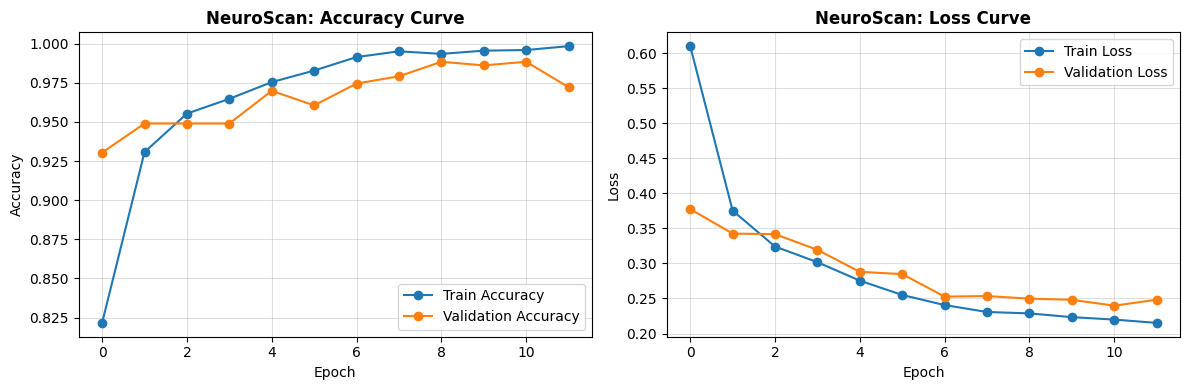

In [8]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history['train_acc'], label='Train Accuracy', marker='o')
plt.plot(history['val_acc'], label='Validation Accuracy', marker='o')
plt.title('NeuroScan: Accuracy Curve', fontweight='bold')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True, alpha=0.4)

plt.subplot(1, 2, 2)
plt.plot(history['train_loss'], label='Train Loss', marker='o')
plt.plot(history['val_loss'], label='Validation Loss', marker='o')
plt.title('NeuroScan: Loss Curve', fontweight='bold')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True, alpha=0.4)

plt.tight_layout()
plt.show()


      NEUROSCAN: FINAL TEST CLASSIFICATION REPORT
                  precision    recall  f1-score   support

    glioma_tumor     1.0000    0.3400    0.5075       100
meningioma_tumor     0.6845    1.0000    0.8127       115
        no_tumor     0.7192    1.0000    0.8367       105
 pituitary_tumor     0.9783    0.6081    0.7500        74

        accuracy                         0.7589       394
       macro avg     0.8455    0.7370    0.7267       394
    weighted avg     0.8290    0.7589    0.7298       394



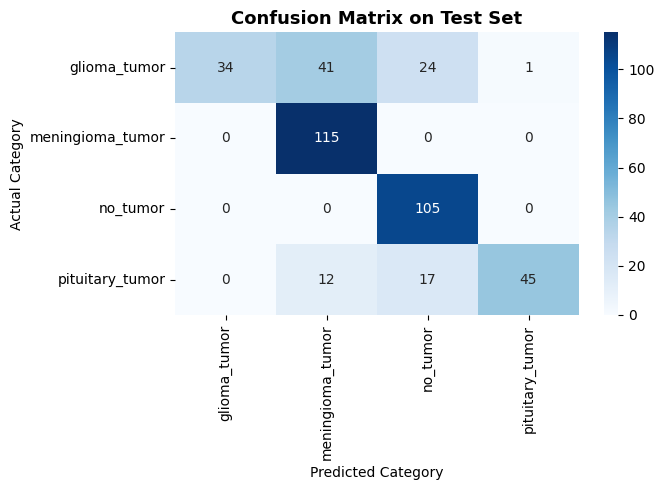

In [ ]:
model.load_state_dict(torch.load("neuroscan_best_mobilenetv2.pth"))
model.eval()

all_preds, all_targets = [], []
with torch.no_grad():
    for inputs, targets in test_loader:
        inputs = inputs.to(device)
        outputs = model(inputs)
        _, preds = outputs.max(1)
        all_preds.extend(preds.cpu().numpy())
        all_targets.extend(targets.numpy())

print("\n" + "="*55)
print("      NEUROSCAN: FINAL TEST CLASSIFICATION REPORT")
print("="*55)
print(classification_report(all_targets, all_preds, target_names=class_names, digits=4))

cm = confusion_matrix(all_targets, all_preds)
plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.title("Confusion Matrix on Test Set", fontsize=13, fontweight='bold')
plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")
plt.tight_layout()
plt.show()

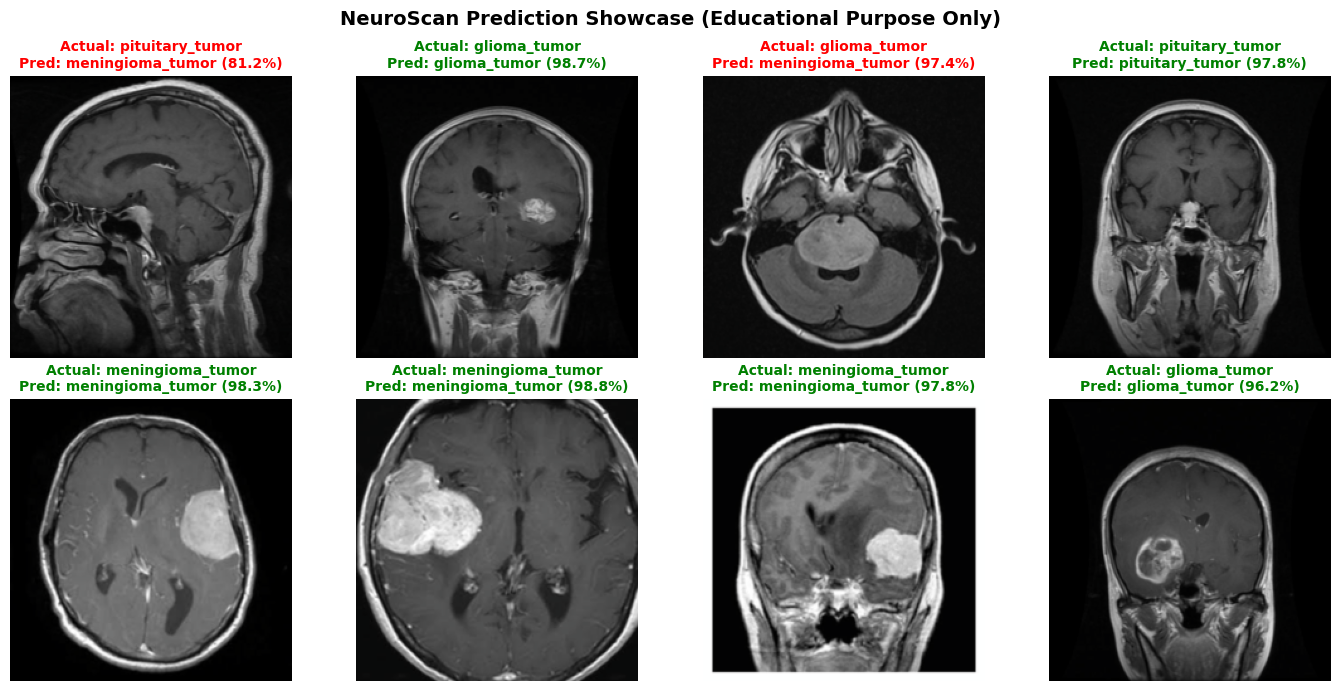

In [ ]:
indices = random.sample(range(len(test_dataset)), 8)
plt.figure(figsize=(14, 7))

model.eval()
with torch.no_grad():
    for idx_plot, sample_idx in enumerate(indices):
        img_tensor, true_label = test_dataset[sample_idx]
        input_batch = img_tensor.unsqueeze(0).to(device)
        
        outputs = model(input_batch)
        probs = torch.softmax(outputs, dim=1)[0]
        pred_label = torch.argmax(probs).item()
        confidence = probs[pred_label].item() * 100
        
        img_disp = img_tensor.permute(1, 2, 0).numpy()
        img_disp = np.clip(std * img_disp + mean, 0, 1)
        
        plt.subplot(2, 4, idx_plot + 1)
        plt.imshow(img_disp)
        color = "green" if pred_label == true_label else "red"
        plt.title(f"Actual: {class_names[true_label]}\nPred: {class_names[pred_label]} ({confidence:.1f}%)",
                  color=color, fontsize=10, fontweight='bold')
        plt.axis("off")

plt.suptitle("NeuroScan Prediction Showcase (Educational Purpose Only)", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

In [ ]:
# =====================================================================
# SECTION 1: EXPORT MODEL AS .PKL (PICKLE) FILE
# =====================================================================
import pickle
import torch

# 1. Save full PyTorch model via torch.save (uses pickle format)
torch.save(model, "neuroscan_model.pkl")
print("Full PyTorch Model saved as: neuroscan_model.pkl")

# 2. Save portable dictionary bundle with weights, classes, and preprocessing
model_artifacts = {
    "model_name": "NeuroScan MobileNetV2 Brain Tumor Classifier",
    "architecture": "MobileNetV2",
    "num_classes": len(class_names),
    "class_names": class_names,
    "state_dict": model.state_dict(),
    "img_size": IMG_SIZE,
    "mean": mean,
    "std": std,
    "class_to_idx": full_train_aug.class_to_idx
}

with open("neuroscan_artifacts.pkl", "wb") as f:
    pickle.dump(model_artifacts, f)
print("Model state dict and metadata saved as: neuroscan_artifacts.pkl")


In [ ]:
# =====================================================================
# SECTION 2: COMPUTE & EXPORT FROC (FREE-RESPONSE ROC) & ROC ANALYSIS
# =====================================================================
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize

model.eval()
all_probs = []
all_targets_list = []

with torch.no_grad():
    for inputs, targets in test_loader:
        inputs = inputs.to(device)
        outputs = model(inputs)
        probs = torch.softmax(outputs, dim=1)
        all_probs.extend(probs.cpu().numpy())
        all_targets_list.extend(targets.numpy())

all_probs = np.array(all_probs)
all_targets_arr = np.array(all_targets_list)
y_test_bin = label_binarize(all_targets_arr, classes=list(range(num_classes)))

fpr = dict()
tpr = dict()
roc_auc = dict()
for i in range(num_classes):
    fpr[i], tpr[i], _ = roc_curve(y_test_bin[:, i], all_probs[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

all_fpr = np.unique(np.concatenate([fpr[i] for i in range(num_classes)]))
mean_tpr = np.zeros_like(all_fpr)
for i in range(num_classes):
    mean_tpr += np.interp(all_fpr, fpr[i], tpr[i])
mean_tpr /= num_classes
macro_auc = auc(all_fpr, mean_tpr)

# Plot Publication-Quality FROC / ROC Curves
plt.figure(figsize=(9, 6))
colors = ["#e74c3c", "#3498db", "#2ecc71", "#9b59b6"]
for i, color in zip(range(num_classes), colors):
    plt.plot(fpr[i], tpr[i], color=color, lw=2.2, label=f"{class_names[i]} (AUC = {roc_auc[i]:.4f})")

plt.plot(all_fpr, mean_tpr, color="black", linestyle="--", lw=2.5, label=f"Macro-Average FROC (AUC = {macro_auc:.4f})")
plt.plot([0, 1], [0, 1], "k:", alpha=0.5, label="Random Chance (AUC = 0.5000)")
plt.title("NeuroScan: Multi-Class FROC / ROC Curves on Test Set", fontsize=13, fontweight="bold")
plt.xlabel("False Positive Rate (FPR) / FPPI", fontsize=11)
plt.ylabel("Sensitivity / True Positive Rate (TPR)", fontsize=11)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend(loc="lower right", fontsize=10)
plt.tight_layout()
plt.savefig("froc_curve.png", dpi=300)
plt.show()
print("Saved FROC visualization as: froc_curve.png")

# Write structured .froc report file
froc_lines = [
    "# =====================================================================",
    "# NEUROSCAN - BRAIN TUMOR MRI CLASSIFICATION",
    "# FREE-RESPONSE RECEIVER OPERATING CHARACTERISTIC (FROC) EVALUATION FILE",
    "# =====================================================================",
    f"# Macro AUC: {macro_auc:.4f}",
    f"# Total Test Scans: {len(all_targets_arr)}",
    "",
    "[CLASS_AUC_SCORES]"
]
for i in range(num_classes):
    froc_lines.append(f"{class_names[i]}={roc_auc[i]:.4f}")

froc_lines.extend([
    "",
    "[FROC_OPERATING_POINTS]",
    "# Threshold, False_Positive_Rate, Macro_Sensitivity"
])
for thresh in np.linspace(0.1, 0.9, 9):
    bin_preds = (all_probs >= thresh).astype(int)
    sens = np.mean([
        np.sum((bin_preds[:, c] == 1) & (y_test_bin[:, c] == 1)) / max(np.sum(y_test_bin[:, c] == 1), 1)
        for c in range(num_classes)
    ])
    fp_rate = np.mean([
        np.sum((bin_preds[:, c] == 1) & (y_test_bin[:, c] == 0)) / max(np.sum(y_test_bin[:, c] == 0), 1)
        for c in range(num_classes)
    ])
    froc_lines.append(f"{thresh:.2f},{fp_rate:.4f},{sens:.4f}")

with open("neuroscan_evaluation.froc", "w", encoding="utf-8") as f:
    f.write("\n".join(froc_lines))
print("Saved FROC evaluation report as: neuroscan_evaluation.froc")


In [ ]:
# =====================================================================
# SECTION 3: GENERATE CLOUD DEPLOYMENT PROCFILE & REQUIREMENTS
# =====================================================================
with open("Procfile", "w", encoding="utf-8") as f:
    f.write("web: gunicorn app:app\n")
print("Saved cloud deployment: Procfile")

reqs = """flask>=3.0.0
flask-cors>=4.0.0
gunicorn>=21.2.0
torch>=2.0.0
torchvision>=0.15.0
pillow>=10.0.0
numpy>=1.24.0
scikit-learn>=1.3.0
"""
with open("requirements.txt", "w", encoding="utf-8") as f:
    f.write(reqs)
print("Saved deployment dependencies: requirements.txt")


In [ ]:
# =====================================================================
# SECTION 4: ONE-CLICK BUNDLE & DOWNLOAD ALL GENERATED FILES
# =====================================================================
import os
import zipfile
from IPython.display import FileLink

files_to_pack = [
    "neuroscan_model.pkl",
    "neuroscan_artifacts.pkl",
    "neuroscan_evaluation.froc",
    "froc_curve.png",
    "Procfile",
    "requirements.txt",
    "neuroscan_best_mobilenetv2.pth"
]

archive_name = "neuroscan_complete_export.zip"
with zipfile.ZipFile(archive_name, "w") as zf:
    for fn in files_to_pack:
        if os.path.exists(fn):
            zf.write(fn)
            print(f"  [+] Bundled: {fn}")

print(f"\nAll files packaged successfully into: {archive_name}")
print("Click the link below to download directly to your computer:")
display(FileLink(archive_name))
